Expectation:- Need a clarity on who is spending more money for shoppping incase of gender, age_group, state, Occupation, Product category, marital status.

In [1]:
# Import necessary libraries for data manipulation and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load sales dataset with ISO-8859-1 encoding to handle special characters
df = pd.read_csv('D:/New folder/temp_repo/sales_data_cleaning/sales_data (4).csv',encoding="ISO-8859-1")
df

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0,NaN,NaN
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0,NaN,NaN
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0,NaN,NaN
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0,NaN,NaN
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11246,1000695,Manning,P00296942,M,18-25,19,1,Maharashtra,Western,Chemical,Office,4,370.0,NaN,NaN
11247,1004089,Reichenbach,P00171342,M,26-35,33,0,Haryana,Northern,Healthcare,Veterinary,3,367.0,NaN,NaN
11248,1001209,Oshin,P00201342,F,36-45,40,0,Madhya Pradesh,Central,Textile,Office,4,213.0,NaN,NaN
11249,1004023,Noonan,P00059442,M,36-45,37,0,Karnataka,Southern,Agriculture,Office,3,206.0,NaN,NaN


In [3]:
# Inspect dataset structure, column data types, and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11251 entries, 0 to 11250
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11251 non-null  int64  
 1   Cust_name         11251 non-null  str    
 2   Product_ID        11251 non-null  str    
 3   Gender            11251 non-null  str    
 4   Age Group         11251 non-null  str    
 5   Age               11251 non-null  int64  
 6   Marital_Status    11251 non-null  int64  
 7   State             11251 non-null  str    
 8   Zone              11251 non-null  str    
 9   Occupation        11251 non-null  str    
 10  Product_Category  11251 non-null  str    
 11  Orders            11251 non-null  int64  
 12  Amount            11239 non-null  float64
 13  Status            0 non-null      float64
 14  unnamed1          0 non-null      float64
dtypes: float64(3), int64(4), str(8)
memory usage: 1.9 MB


In [4]:
# Generate summary statistics (mean, std, min, max, percentiles) for numeric columns
df.describe()

,User_ID,Age,Marital_Status,Orders,Amount,Status,unnamed1
count,1.125100e+04,11251.000000,11251.000000,11251.000000,11239.000000,0.0,0.0
mean,1.003004e+06,35.421207,0.420318,2.489290,9453.610858,NaN,NaN
std,1.716125e+03,12.754122,0.493632,1.115047,5222.355869,NaN,NaN
min,1.000001e+06,12.000000,0.000000,1.000000,188.000000,NaN,NaN
25%,1.001492e+06,27.000000,0.000000,1.500000,5443.000000,NaN,NaN
50%,1.003065e+06,33.000000,0.000000,2.000000,8109.000000,NaN,NaN
75%,1.004430e+06,43.000000,1.000000,3.000000,12675.000000,NaN,NaN
max,1.006040e+06,92.000000,1.000000,4.000000,23952.000000,NaN,NaN


In [5]:
# Remove duplicate rows and verify that duplicate count is 0
df = df.drop_duplicates()
df.duplicated().sum()


np.int64(0)

In [6]:
# Check count of missing / null values across all columns
df.isnull().sum()

User_ID                 0
Cust_name               0
Product_ID              0
Gender                  0
Age Group               0
Age                     0
Marital_Status          0
State                   0
Zone                    0
Occupation              0
Product_Category        0
Orders                  0
Amount                 12
Status              11243
unnamed1            11243
dtype: int64

In [7]:
# List all column names in the dataset
df.columns

Index(['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age',
       'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category',
       'Orders', 'Amount', 'Status', 'unnamed1'],
      dtype='str')

In [8]:
# Drop unused columns with entirely missing/irrelevant data ('Status' and 'unnamed1')
df.drop(['Status','unnamed1'],axis=1,inplace=True)

In [9]:
# Impute missing values in 'Amount' with the mean value, then verify no nulls remain
df['Amount'] = df['Amount'].fillna(df['Amount'].mean())
df['Amount'].isnull().sum()

np.int64(0)

In [10]:
# Keep this standardized before grouping/plotting, otherwise 'F' and 'female' split into two categories
# Standardize gender abbreviations to descriptive labels ('F' -> 'female', 'M' -> 'male')
df['Gender'] = df['Gender'].replace({'F':"female",'M':'male'})
df

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount
0,1002903,Sanskriti,P00125942,female,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0
1,1000732,Kartik,P00110942,female,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0
2,1001990,Bindu,P00118542,female,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0
3,1001425,Sudevi,P00237842,male,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0
4,1000588,Joni,P00057942,male,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11246,1000695,Manning,P00296942,male,18-25,19,1,Maharashtra,Western,Chemical,Office,4,370.0
11247,1004089,Reichenbach,P00171342,male,26-35,33,0,Haryana,Northern,Healthcare,Veterinary,3,367.0
11248,1001209,Oshin,P00201342,female,36-45,40,0,Madhya Pradesh,Central,Textile,Office,4,213.0
11249,1004023,Noonan,P00059442,male,36-45,37,0,Karnataka,Southern,Agriculture,Office,3,206.0


In [11]:
# Marital status was numeric in the raw file, so decode it into readable labels
# Convert marital status to string and map values (0: single, 1: married)
df['Marital_Status'] = df['Marital_Status'].astype(str)
df['Marital_Status'] = df['Marital_Status'].replace({'0':'single','1':'married'})
df

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount
0,1002903,Sanskriti,P00125942,female,26-35,28,single,Maharashtra,Western,Healthcare,Auto,1,23952.0
1,1000732,Kartik,P00110942,female,26-35,35,married,Andhra Pradesh,Southern,Govt,Auto,3,23934.0
2,1001990,Bindu,P00118542,female,26-35,35,married,Uttar Pradesh,Central,Automobile,Auto,3,23924.0
3,1001425,Sudevi,P00237842,male,0-17,16,single,Karnataka,Southern,Construction,Auto,2,23912.0
4,1000588,Joni,P00057942,male,26-35,28,married,Gujarat,Western,Food Processing,Auto,2,23877.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11246,1000695,Manning,P00296942,male,18-25,19,married,Maharashtra,Western,Chemical,Office,4,370.0
11247,1004089,Reichenbach,P00171342,male,26-35,33,single,Haryana,Northern,Healthcare,Veterinary,3,367.0
11248,1001209,Oshin,P00201342,female,36-45,40,single,Madhya Pradesh,Central,Textile,Office,4,213.0
11249,1004023,Noonan,P00059442,male,36-45,37,single,Karnataka,Southern,Agriculture,Office,3,206.0


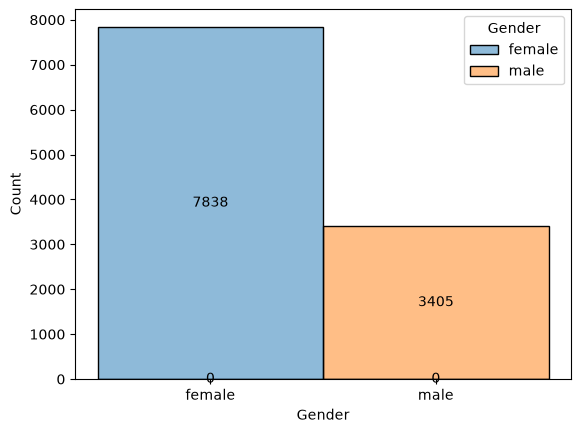

In [12]:
# Bar labels show exact customer counts per gender, making the split readable at a glance
# Visualize customer count distribution by gender with centered count labels
a = sns.histplot(x='Gender',data=df,hue='Gender')
for i in a.containers:
    a.bar_label(i,label_type='center')

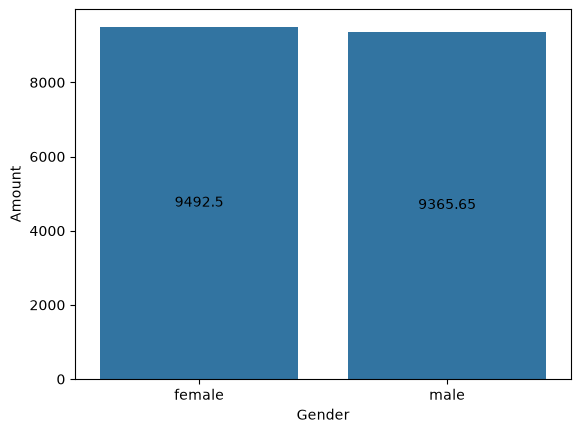

In [13]:
# errorbar=None removes the confidence interval bars so the mean spend comparison stays clean
# Visualize average spending amount by gender with centered value labels
a = sns.barplot(x='Gender',y='Amount',data=df,errorbar=None)
for i in a.containers:
    a.bar_label(i,label_type='center')

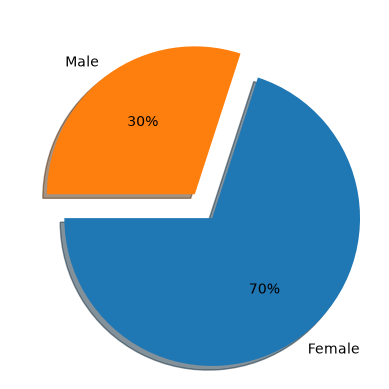

In [14]:
# Pie slices compare total spend share: female vs male customers
# Calculate total spending by gender and plot the proportional share using a pie chart
fe =df[df['Gender']=='female']['Amount'].sum()
ma = df[df['Gender']=='male']['Amount'].sum()
l = [fe,ma]
plt.pie(l,labels=['Female','Male'],autopct="%0.0f%%",shadow=True, explode=[0.2,0],startangle=180)

In [15]:
# Reusable helper: annotate every bar in a seaborn/matplotlib container with its value
def labels(lab):
    for i in lab.containers:
        lab.bar_label(i)

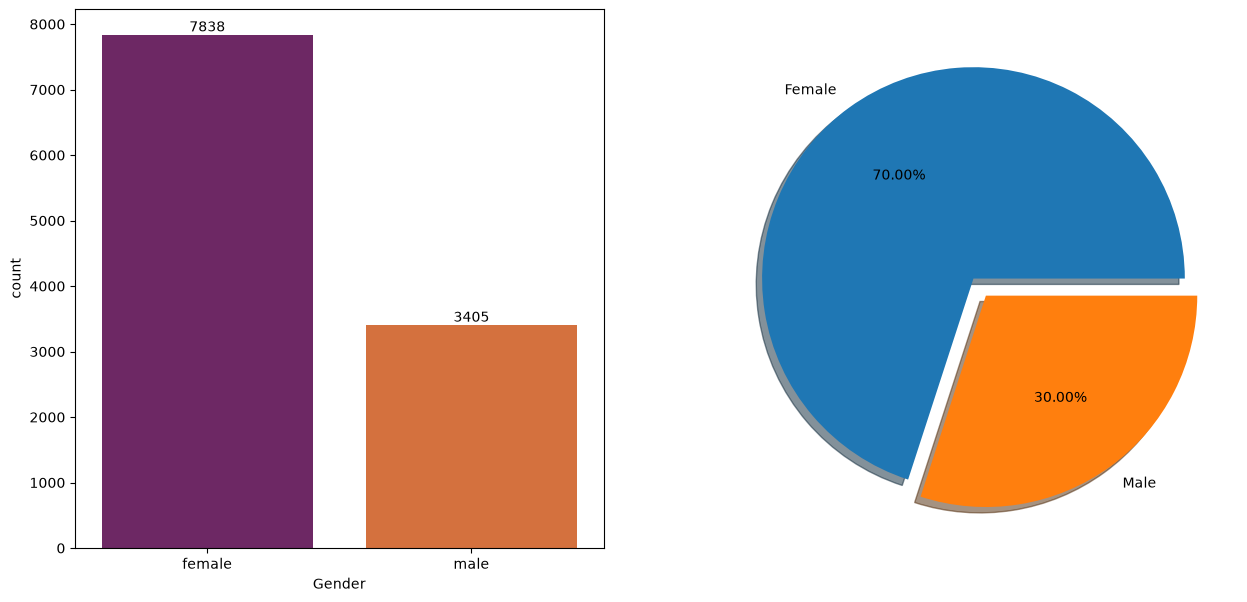

In [16]:
# Side-by-side view: left = customer count per gender, right = share of total spend per gender
fig, axes = plt.subplots(nrows=1,ncols=2,figsize=(15,7))
a = sns.countplot(x='Gender',data=df,hue='Gender',palette='inferno',ax=axes[0])
labels(a)
g_g = df.groupby('Gender')['Amount'].sum()
plt.pie(g_g,labels=['Female','Male'],explode=[0,0.1],shadow=True,autopct='%0.2f%%')

In [17]:
df

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount
0,1002903,Sanskriti,P00125942,female,26-35,28,single,Maharashtra,Western,Healthcare,Auto,1,23952.0
1,1000732,Kartik,P00110942,female,26-35,35,married,Andhra Pradesh,Southern,Govt,Auto,3,23934.0
2,1001990,Bindu,P00118542,female,26-35,35,married,Uttar Pradesh,Central,Automobile,Auto,3,23924.0
3,1001425,Sudevi,P00237842,male,0-17,16,single,Karnataka,Southern,Construction,Auto,2,23912.0
4,1000588,Joni,P00057942,male,26-35,28,married,Gujarat,Western,Food Processing,Auto,2,23877.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11246,1000695,Manning,P00296942,male,18-25,19,married,Maharashtra,Western,Chemical,Office,4,370.0
11247,1004089,Reichenbach,P00171342,male,26-35,33,single,Haryana,Northern,Healthcare,Veterinary,3,367.0
11248,1001209,Oshin,P00201342,female,36-45,40,single,Madhya Pradesh,Central,Textile,Office,4,213.0
11249,1004023,Noonan,P00059442,male,36-45,37,single,Karnataka,Southern,Agriculture,Office,3,206.0


C:\Users\ABHISHEK SHARMA\AppData\Local\Temp\ipykernel_20916\135217356.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  a = sns.barplot(x='Age Group',y='Amount',data=df,estimator='sum',palette='Set2',ax=axes[0],errorbar=None)
C:\Users\ABHISHEK SHARMA\AppData\Local\Temp\ipykernel_20916\135217356.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  a = sns.barplot(y='State',x='Amount',data=df,estimator='sum',palette='Set2',errorbar=None)


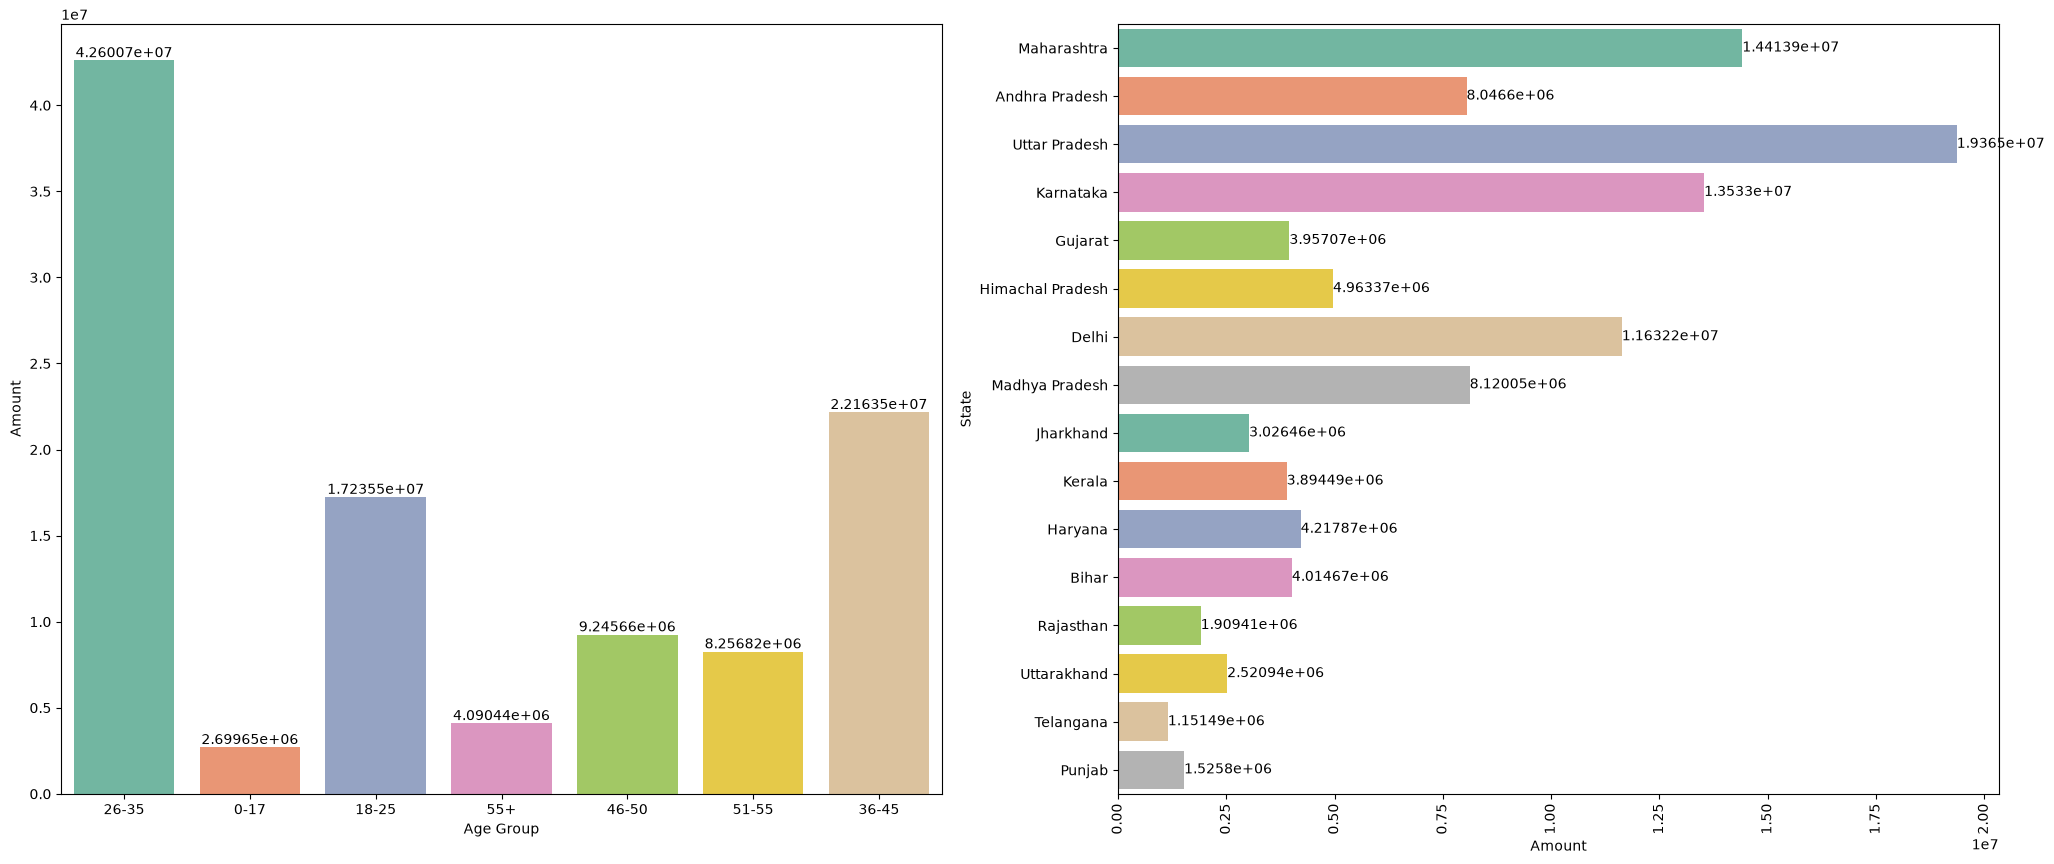

In [18]:
# Compare total spend across age groups (left) and across states (right)
fig_1, axes = plt.subplots(nrows=1,ncols=2,figsize=(25,10))
a = sns.barplot(x='Age Group',y='Amount',data=df,estimator='sum',palette='Set2',ax=axes[0],errorbar=None)
labels(a)
a = sns.barplot(y='State',x='Amount',data=df,estimator='sum',palette='Set2',errorbar=None)
plt.xticks(rotation=90)
labels(a)
# age_gp = df.groupby('Age Group')['Amount'].sum()
# age_lb = df['Age Group'].unique()
# plt.pie(age_gp,labels=age_lb,autopct="%0.0f%%",explode=[0.2,0.1,0.1,0.1,0.1,0.1,0.2])

In [19]:
# Inspect all distinct state values before aggregating, to catch naming inconsistencies
df['State'].unique()

<ArrowStringArray>
[     'Maharashtra',   'Andhra Pradesh',    'Uttar Pradesh',
        'Karnataka',          'Gujarat', 'Himachal Pradesh',
            'Delhi',   'Madhya Pradesh',        'Jharkhand',
           'Kerala',          'Haryana',            'Bihar',
        'Rajasthan',      'Uttarakhand',        'Telangana',
           'Punjab']
Length: 16, dtype: str

In [20]:
# Reset index turns State into a regular column so the result is easy to reuse for plotting
# Group by State and sum Amount, sorted from highest to lowest spender
state_total = df.groupby('State')['Amount'].sum().sort_values(ascending=False).reset_index()

print(state_total)

               State        Amount
0      Uttar Pradesh  1.936496e+07
1        Maharashtra  1.441392e+07
2          Karnataka  1.353299e+07
3              Delhi  1.163218e+07
4     Madhya Pradesh  8.120050e+06
5     Andhra Pradesh  8.046601e+06
6   Himachal Pradesh  4.963368e+06
7            Haryana  4.217871e+06
8              Bihar  4.014669e+06
9            Gujarat  3.957067e+06
10            Kerala  3.894492e+06
11         Jharkhand  3.026456e+06
12       Uttarakhand  2.520944e+06
13         Rajasthan  1.909409e+06
14            Punjab  1.525800e+06
15         Telangana  1.151490e+06


C:\Users\ABHISHEK SHARMA\AppData\Local\Temp\ipykernel_20916\579026913.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  a = sns.barplot(data=df,y='State',x='Amount',errorbar=None,estimator='sum',palette='Set2')


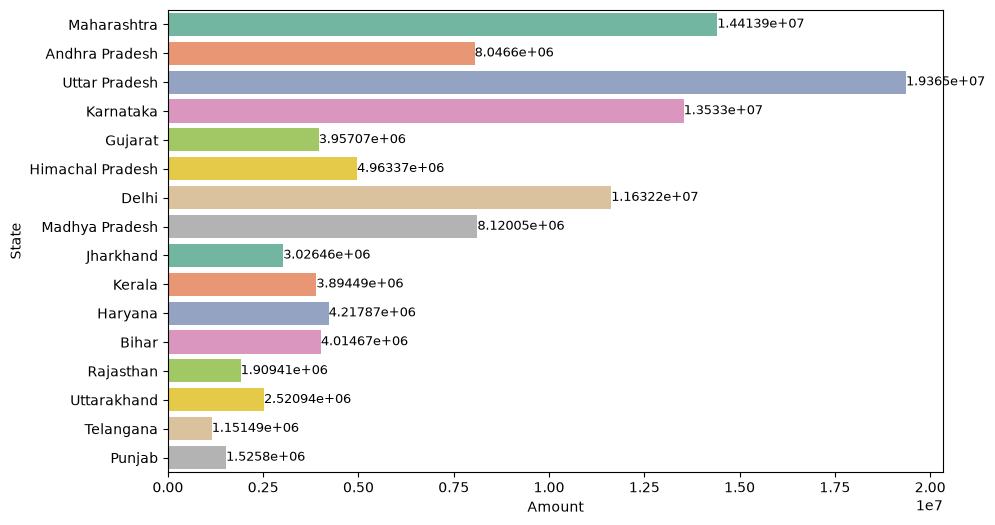

In [21]:
# Horizontal bar chart of state-wise spend, sorted naturally by the groupby above; labels at fontsize 9 to fit long state names
plt.figure(figsize=(10,6))
a = sns.barplot(data=df,y='State',x='Amount',errorbar=None,estimator='sum',palette='Set2')
for i in a.containers:
    a.bar_label(i,fontsize=9)
plt.show()

In [22]:
# Inspect all distinct occupations present in the data
df['Occupation'].unique()

<ArrowStringArray>
[     'Healthcare',            'Govt',      'Automobile',    'Construction',
 'Food Processing',          'Lawyer',       'IT Sector',           'Media',
         'Banking',          'Retail',     'Hospitality',        'Aviation',
     'Agriculture',         'Textile',        'Chemical']
Length: 15, dtype: str

C:\Users\ABHISHEK SHARMA\AppData\Local\Temp\ipykernel_20916\45914675.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  a = sns.barplot(data=df,x='Amount',y='Occupation',estimator='sum',errorbar=None,palette='Set2')


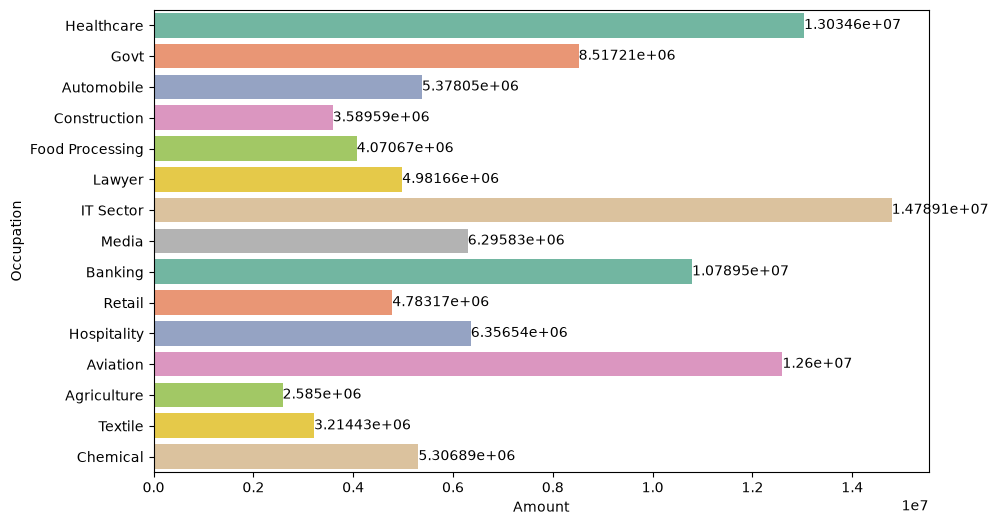

In [23]:
# Occupation-wise total spend: which job profiles contribute the most revenue
plt.figure(figsize=(10,6))
a = sns.barplot(data=df,x='Amount',y='Occupation',estimator='sum',errorbar=None,palette='Set2')
for i in a.containers:
    a.bar_label(i)

In [24]:
# Inspect all distinct product categories
df['Product_Category'].unique()

<ArrowStringArray>
[                 'Auto',    'Hand & Power Tools',            'Stationery',
            'Tupperware',      'Footwear & Shoes',             'Furniture',
                  'Food',          'Games & Toys',       'Sports Products',
                 'Books', 'Electronics & Gadgets',                 'Decor',
    'Clothing & Apparel',                'Beauty',       'Household items',
              'Pet Care',            'Veterinary',                'Office']
Length: 18, dtype: str

C:\Users\ABHISHEK SHARMA\AppData\Local\Temp\ipykernel_20916\1036263382.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  a = sns.barplot(data=df,x='Amount',y='Product_Category',errorbar=None,estimator='sum',palette='Set2')


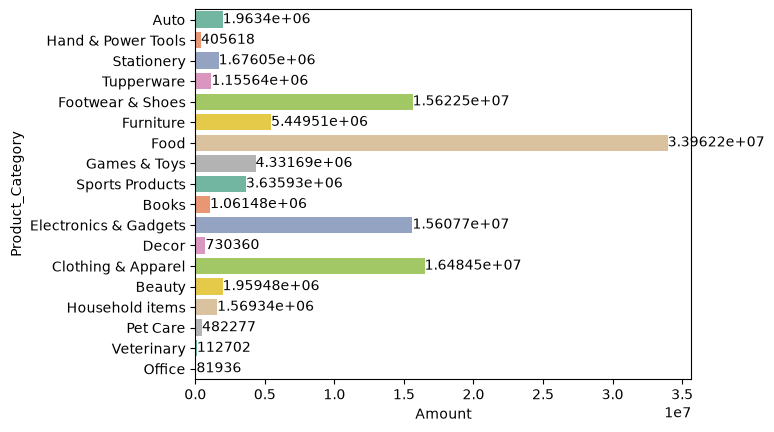

In [25]:
# Product-category-wise total spend: where the money actually goes (food, clothing, electronics, etc.)
a = sns.barplot(data=df,x='Amount',y='Product_Category',errorbar=None,estimator='sum',palette='Set2')
for i in a.containers:
    a.bar_label(i)

C:\Users\ABHISHEK SHARMA\AppData\Local\Temp\ipykernel_20916\3437712495.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  a = sns.barplot(data=df,x='Marital_Status',y='Amount',palette='Set2',errorbar=None,ax=axes[0])


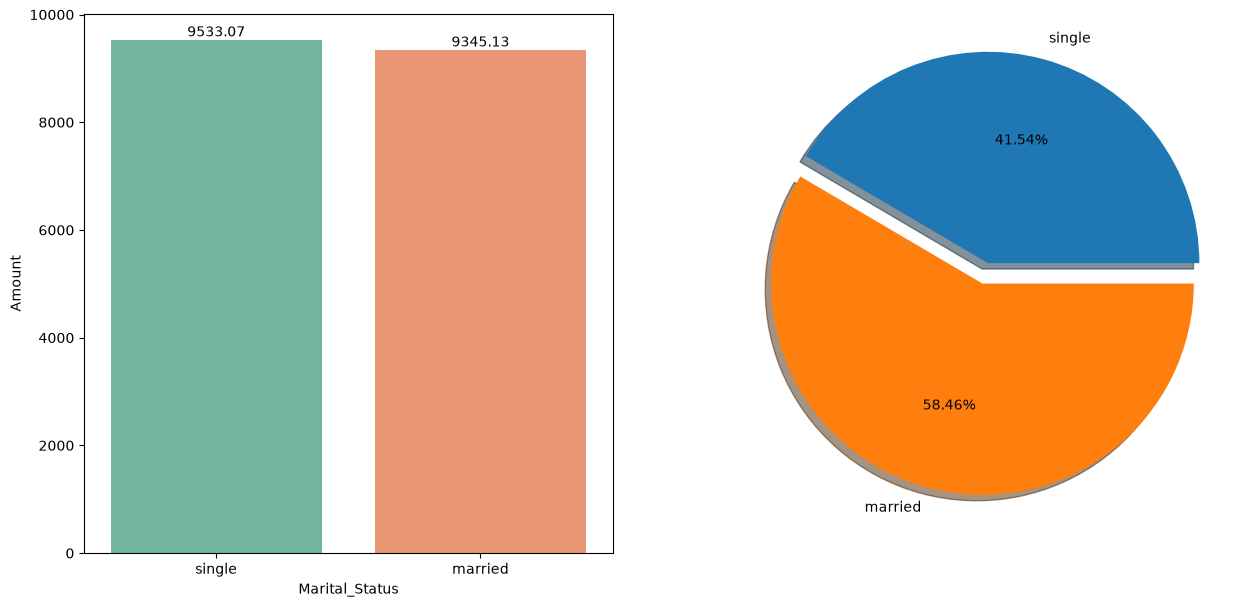

In [26]:
# Marital status view: left = total spend per status, right = share of overall spend (single vs married)
fig_2,axes = plt.subplots(nrows=1,ncols=2,figsize=(15,7))
a = sns.barplot(data=df,x='Marital_Status',y='Amount',palette='Set2',errorbar=None,ax=axes[0])
labels(a)
l = df['Marital_Status'].unique()
st = df.groupby('Marital_Status')['Amount'].sum()
plt.pie(st,labels=l,autopct='%0.2f%%',shadow=True,explode=[0.1,0])

In [27]:
df

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount
0,1002903,Sanskriti,P00125942,female,26-35,28,single,Maharashtra,Western,Healthcare,Auto,1,23952.0
1,1000732,Kartik,P00110942,female,26-35,35,married,Andhra Pradesh,Southern,Govt,Auto,3,23934.0
2,1001990,Bindu,P00118542,female,26-35,35,married,Uttar Pradesh,Central,Automobile,Auto,3,23924.0
3,1001425,Sudevi,P00237842,male,0-17,16,single,Karnataka,Southern,Construction,Auto,2,23912.0
4,1000588,Joni,P00057942,male,26-35,28,married,Gujarat,Western,Food Processing,Auto,2,23877.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11246,1000695,Manning,P00296942,male,18-25,19,married,Maharashtra,Western,Chemical,Office,4,370.0
11247,1004089,Reichenbach,P00171342,male,26-35,33,single,Haryana,Northern,Healthcare,Veterinary,3,367.0
11248,1001209,Oshin,P00201342,female,36-45,40,single,Madhya Pradesh,Central,Textile,Office,4,213.0
11249,1004023,Noonan,P00059442,male,36-45,37,single,Karnataka,Southern,Agriculture,Office,3,206.0


<Axes: xlabel='Age Group', ylabel='Amount'>

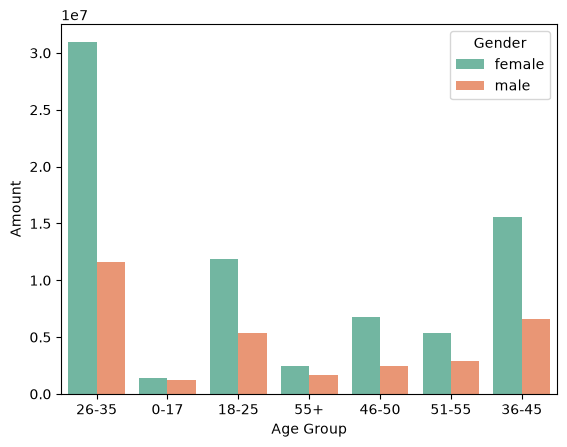

In [30]:
# Age Group x Gender: which age-gender combination spends the most overall
sns.barplot(data=df,x='Age Group',y='Amount',hue='Gender',palette='Set2',errorbar=None,estimator='sum')

## What else can we do with this dataset?

The current analysis answers *who spends more*. The same cleaned dataframe can go much further:

**1. Age-group deep dive**
- Combine `Age Group` + `Gender` into a grouped bar chart (`hue='Gender'`) to see which age-gender pair is the real high spender.
- Box plot / violin plot of `Amount` per `Age Group` to compare not just totals but spread and outliers.

**2. State-level story**
- Top 5 vs bottom 5 states by total spend, and by *average* spend per order (a small state can still have big buyers).
- State × Product_Category heatmap (`sns.heatmap` on a pivot table) to find regional product preferences.
- Map the states onto India's regions (North/South/East/West) and compare regional spend.

**3. Product category and orders**
- `Orders` vs `Amount` scatter plot to check whether big spenders are buying more items or pricier items.
- Revenue contribution: each Product_Category's share of total spend, with cumulative % (Pareto / 80-20 analysis).
- Average order value per category, not just the sum.

**4. Occupation and customer segments**
- Occupation × Gender, Occupation × Age Group crosstabs to profile each profession.
- Average spend per customer per occupation (total spend ÷ number of customers), which corrects for occupations having more buyers.

**5. Marital status and family angle**
- Marital status × Product_Category: do married customers buy different things?
- Compare single vs married spend within each age group (interaction effect).

**6. Statistics and rigor**
- Correlation matrix of numeric columns (`Orders`, `Amount`, and encoded categoricals).
- Hypothesis test (t-test / ANOVA) to check whether the gender difference in spending is statistically significant, not just a visual gap.
- Skewness of `Amount` and a log transform if the distribution is heavily right-skewed.

**7. Data quality follow-ups**
- Imputing `Amount` with the *mean* pulls the distribution toward the centre; compare with median or group-wise median imputation.
- Validate the categorical columns (`State`, `Occupation`) for typos / mixed spellings before trusting the groupby totals.

**8. Reporting**
- Export a small summary table (spend by gender, state, occupation, category, marital status) to CSV or Excel for sharing.
- Add the key numbers as annotations on the charts instead of relying on bar labels alone.



Conclusion: Based on the above analysis I can conclude that Females of 26-35 from Uttar-Pradesh, Maharashtra and Karnataka working IT, Healthcare and Aviation spend more money on Food, clothes and footware and Electrocin gadgets.